In [1]:
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

In [2]:
## For full notes of what each part of the script does, see individual python scripts

In [3]:
PLOT_CONFIG = {
    "figure_default": (12, 6),
    "figure_large": (14, 8),
    "figure_medium": (10, 6),
    "figure_scatter": (10, 8),
    "bar_color_green": "#4CAF50",
    "palette_yellow_red": "YlOrRd",
    "palette_viridis": "viridis",
    "rotation": 45,
}

def create_vbar_plot(data: pd.DataFrame, x_col: str, y_col: str,
                    title: str, x_label: str, y_label: str,
                    figsize: tuple = None, palette: str = None,
                    rotate_x: bool = True) -> plt.Figure:
    """Reusable vertical bar plot."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_default"])

    sns.barplot(
        x=x_col,
        y=y_col,
        data=data,
        hue=x_col,
        palette=palette or PLOT_CONFIG["palette_yellow_red"],
        legend=False
    )

    if rotate_x:
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(ax.get_xticklabels(), rotation=PLOT_CONFIG["rotation"], ha="right")

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    plt.tight_layout()
    return fig

def create_hbar_plot(data: pd.DataFrame, x_col: str, y_col: str,
                    title: str, x_label: str, y_label: str,
                    figsize: tuple = None, color: str = None) -> plt.Figure:
    """Reusable horizontal bar plot."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_default"])

    bars = ax.barh(
        data[y_col],
        data[x_col],
        color=color or PLOT_CONFIG["bar_color_green"],
        edgecolor="white",
        linewidth=0.5
    )

    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel(y_label, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.invert_yaxis()
    plt.tight_layout()
    return fig

def create_histogram_with_kde(data: pd.DataFrame, column: str,
                             title: str, x_label: str, y_label: str,
                             color: str = "green", figsize: tuple = None) -> plt.Figure:
    """Reusable histogram with KDE overlay."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_medium"])

    sns.histplot(
        data=data,
        x=column,
        kde=True,
        color=color,
        stat='density',
        alpha=0.8
    )

    sns.despine()
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    plt.tight_layout()
    return fig

def create_scatter_clustering(X: np.ndarray, labels: np.ndarray,
                             var_explained: tuple, title: str = None,
                             figsize: tuple = None) -> plt.Figure:
    """Reusable PCA/UMAP scatter plot for clustering."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_scatter"])

    scatter = ax.scatter(
        X[:, 0], X[:, 1],
        c=labels,
        cmap=PLOT_CONFIG["palette_viridis"],
        alpha=0.6,
        s=100,
        edgecolors='black'
    )

    ax.set_xlabel(f'PC1 ({var_explained[0]:.1%})')
    ax.set_ylabel(f'PC2 ({var_explained[1]:.1%})')
    ax.set_title(title or 'Clustering Visualization', fontsize=14, fontweight="bold")
    ax.grid(True, alpha=0.3)

    cbar = plt.colorbar(scatter, label='Cluster')
    cbar.set_label('Cluster', fontsize=12)

    plt.tight_layout()
    return fig

In [4]:
df = pd.read_csv("/Users/hannahehrlich/Documents/programming/drugs_and_side_effects/drugs_side_effects_drugs_com.csv", index_col=False)
df.drop(df.columns[df.columns.str.contains('unnamed', case=False)], axis=1, inplace=True)

df = df.drop(columns=["drug_link", "medical_condition_url"])

df["no_of_reviews"] = pd.to_numeric(
    df["no_of_reviews"].astype(str).str.replace(",", "").str.strip(),
    errors="coerce"
)
df["rating"] = pd.to_numeric(
    df["rating"].astype(str).str.replace(",", "").str.strip(),
    errors="coerce"
)

DRUG_SYNONYM_MAP = {
    "zyprexa zydis": "zyprexa",
}

df["drug_name"] = (
    df["drug_name"]
    .str.strip().str.lower()
    .replace(DRUG_SYNONYM_MAP)
)

In [5]:
LENGTH_CONSTRAINTS = {
    "max_effect_length": 45,
    "min_effect_length": 6,
    "max_words_per_effect": 5,
}

PRE_SPLIT_PATTERNS = [
    r'https?://\S+',
    r'\bwww\.[a-z0-9.-]+\.[a-z]{2,}\S*',
    r'\bfunction\b[^;}{]*',
    r'\bvar\s+[^;]*;',
    r'@?[a-z_$][\w$]*\.(?:push|append|appendChild|'
    r'removeChild|getElementById|querySelector|'
    r'addEventListener|setAttribute|createElement)'
    r'\s*\([^;]{0,200}',
    r'\b(?:window|document)\.\w+',
    r'\bdataLayer\b|\bgoogle_tag|\bgpt\b',
    r'\bconsole\.\w+\s*\([^;]{0,200}',
    r'\b(?:get|set)Time(?:out)?\b',
    r'\b(?:if|else|return|try|catch|new)\b(?=\s*[\(\w])',
]

LEAD_IN_RE = re.compile(
    r"^(get emergency medical help|seek medical (treatment|help|attention)"
    r"|call your doctor[\w\s,]*"
    r"|check with your (doctor|health ?care professional|healthcare professional)[\w\s,]*"
    r"|stop using [\w\s]+|common side effects of [\w\s]+"
    r"|[\w\s]*side effects may include|symptoms may include"
    r"|[a-z\s]+ may cause (serious )?side effects"
    r"|this reaction may occur[\w\s]*"
    r"|some side effects may occur[\w\s]*"
    r"|other side effects not listed[\w\s]*"
    r"|you may report side effects[\w\s]*"
    r"|if you notice any other effects[\w\s,.]*"
    r")[:.\s]*"
    r"|along with its needed effects[\w\s,]*"
    r"|(a )?medicine may cause some unwanted effects[\w\s,.]*",
    re.I
)

SECTION_HEADERS = re.compile(
    r"\b(less common( or rare)?|more common|incidence not known"
    r"|symptoms of (overdose|resorcinol poisoning)[\w\s]*"
    r")\b[:,]?\s*",
    re.I
)

TRAILING_TITLE_RE = re.compile(r"\b[a-z]+\s+side effects\s*$", re.I)

ALLERGIC_SYMPTOMS = re.compile(
    r"^.*signs of an allergic reaction[,:]?\s*", re.I
)

CODE_CONFIG_PATTERNS = [
    r'[{}<>]',
    r'["\']',
    r'[/:_]',
    r'&&|\|\||!=?|=+',
    r'\b(function\s*\(|\.prototype\b|console\.)\b',
    r'\b(getElement|querySelector|setAttribute|addEventListener)\b',
    r'\b(var\s+\w+\s*=|=\s*"\w+)\b',
    r'px$|\d+px',
    r'\b(?=[a-z0-9]*\d)[a-z0-9]{6,}\b',
    r'\batob\(',
    r'\b(if|else|return|try|catch)\b',
    r'\bhttps?:',
    r"(\.prototype\b|atob\(|btoa\(|append\s*child|remove\s*child"
    r"|querySelector|getElementById|addEventListener|\.push\("
    r"|document\.|window\.|function\s*\(|ddc-reference|reference\.?\s*list"
    r"|\.append\(|\.remove\(|\{\s*[\w-]+\s*:"
    r"|console\.|=>|\$\(|===|!==)"
]

INGREDIENT_PATTERNS = [
    r'\b(sodium|chloride|lactose)\b',
    r'\b(mg|g|ml|%|tablet|capsule|injection|antibiotic[s]?)\b',
    r'\b(syrup|solution|gel|cream|ointment|advil|dose[s]?|vapo)\b',
    r'\b(insulin|sulfonylurea|metformin)\b'
]

BOILERPLATE_PATTERNS = [
    r'\b(information|storage|protect|children|vitamin[s]?|prescription[s]?)\b',
    r'\b(devices|available|flavoring|smith|kline|reserved|share|html|mailto|lazy)\b',
    r'\b(alert[s]?|newsletter[s]?|update[s]?)\b',
    r'\b(healthcare|professional[s]?|pharmacist[s]?)\b',
    r'\b(do not|don\'t).*freeze\b',
    r'\bprotect.*from.*(light|moisture|heat)\b',
    r'\b(care provider|emergency medical|medical help|medical attention)\b',
    r'\b(dose|months after|weeks after|last dose)\b',
    r'\b(needed effects|unwanted effects|medicine may cause)\b',
    r'\balong with its needed effects\b',
    r'\bstop using this medicine|stop using\b',
    r'\bmay cause serious side effects\b',
    r'\bcommon side effects of\b',
    r'\bsome side effects may occur during\b',
    r'\bany signs of a new infection\b',
    r'\bwhich can be fatal\b',
    r'\bstop taking this medicine\b',
    r'\bhad no reaction\b',
    r'\buse caution to avoid falling\b',
    r'\bwill not cause [any]? harm\b',
    r'\bthis may include [walking]?\b',
    r'\byou may have none at all\b',
    r'\bdeath may occur\b',
    r'\b(vaccine|vaccination|booster)\b',
    r'\bin (the )?past\b',
    r'\b(identify pills|drug approvals|email to a friend)\b',
    r'\b(diagnosis or treatment|fda approval status)\b',
    r'\bnav-tabs|footer-feature|topbanner-wrap\b',
    r'^[a-z]+\. [a-z]',
]

JUNK_KEYWORDS = [
    "bothersome", "count",
    "modal", "group", "inset", "media", "table", "query", "lower",
    "multi", "propa", "kwik", "log", "nitro", "covid",
    "chlor", "nytol", "facebook", "twitter", "pinterest", "pills", "approvals", "friend",
    "ddc", "accordion", "widget", "sidebar", "viewport", "selector",
    "wrap", "buffer", "license", "xmlhttp", "json", "btoa", "timeout",
    "element", "node", "math", "docs", "blackbox", "diagnosis",
]

VALID_SHORT_WORDS = {
    "rash", "pain", "itch", "fever", "cough", "hives",
    "swelling", "bruising", "blistering", "peeling", "numbness",
    "vomiting", "diarrhea", "dizziness", "nausea", "vertigo",
    "insomnia", "anorexia", "itching", "bleeding", "bloating"
}

DRUG_TOKENS = {
    tok
    for name in df["drug_name"].dropna().unique()
    for tok in re.findall(r"[a-z]{5,}", name)
} - VALID_SHORT_WORDS

def is_drug_name_leak(effect: str) -> bool:
    """Term opens with a known drug name -> it's a sentence fragment."""
    if not effect:
        return True
    return effect.split()[0] in DRUG_TOKENS

EXPLICIT_BLACKLIST = {
    "along with its needed effects", "unwanted effects", "needed effects",
    "people who", "in rare cases", "rare cases", "sometimes death",
    "does not go away", "especially on face", "in those who are debilitated",
    "green in color", "in some cases", "aqua gem", "at night", "not at all",
    "keep all drugs in safe place", "mark clear", "in back", "more often",
    "store in dry place", "around eyes", "reduce some of these side effects",
    "without fever", "report any new", "accidental injury", "worsening symptoms to doctor",
    "like feeling", "allergic reaction can be severe", "stop using unisom sleep gels",
    "ketamine may cause serious side effects", "in premature", "nevi you already have",
    "interferon gamma", "often with a purple center red", "changes in shape",
    "call doctor for medical advice", "peeling skin or without fever"
}

BODY_PARTS = {
        "eye", "eyes", "hand", "hands", "foot", "feet", "leg", "legs",
        "arm", "arms", "finger", "fingers", "toe", "toes", "lip", "lips",
        "tongue", "mouth", "nose", "shoulder", "shoulders", "chest",
        "back", "stomach", "head", "neck", "ear", "ears", "thigh", "thighs",
        "knee", "knees", "wrist", "wrists", "ankle", "ankles", "hip", "hips",
        "waist", "belly", "breast", "breasts", "face", "bone", "throat",
        "body", "fingernail beds", "fingernail", "fingernails"
    }

SPACE_RE = re.compile(r"\s+")

EDGE_PUNCT_RE = re.compile(
    r"^[^\w\s]+|[^\w\s]+$"
)

LEADING_WORDS_RE = re.compile(
    r"^(?:"
    r"or|and|with|including|such|a|an|the|your|that|is|are|"
    r"as|signs?|"
    r"ongoing|sudden|new|any|"
    r"mild|moderate|severe|serious|unusual|persistent|"
    r"very bad"
    r")\s+",
    re.I
)

YOUR_THE_RE = re.compile(
    r"\b(your|the)\b",
    flags=re.I
)

MAY_INCLUDE_RE = re.compile(
    r"^(at once|if you have|may include|that can affect)[\w\s:]*",
    flags=re.I
)

DUPLICATE_WORD_RE = re.compile(
    r"\b(\w+)(\s+\1\b)+",
    flags=re.I
)

ARTICLE_RE = re.compile(
    r"^(?:a|an|the)\s+",
    flags=re.I
)

LOWER_UPPER_RE = re.compile(
    r"([a-z])([A-Z])"
)

SEPARATOR_RE = r"[.;,:]|\n|\s-\s|-{2,}|•"
PRE_SPLIT_REGEX = re.compile("|".join(PRE_SPLIT_PATTERNS), re.I)
INGREDIENT_REGEX = re.compile("|".join(INGREDIENT_PATTERNS), re.I)
BOILERPLATE_REGEX = re.compile("|".join(BOILERPLATE_PATTERNS), re.I)
JUNK_REGEX = re.compile(r"\b(?:" + "|".join(JUNK_KEYWORDS) + r")\b", re.I)
CODE_REGEX = re.compile("|".join(CODE_CONFIG_PATTERNS), re.I)
ALPHANUMERIC_MIX_PATTERN = re.compile(
    r'^(?=.*[a-zA-Z])(?=.*[0-9])[a-zA-Z0-9]+$', re.I
)

In [6]:
def strip_code_segments(text: str) -> str:
    if not isinstance(text, str):
        return text
    return PRE_SPLIT_REGEX.sub(" ", text)

def clean_cell(text: str) -> str:
    txt = str(text)

    txt = ALLERGIC_SYMPTOMS.sub("", txt)
    txt = SPACE_RE.sub(" ", txt).strip()
    txt = LEADING_WORDS_RE.sub("", txt)
    txt = SECTION_HEADERS.sub(". ", txt)
    txt = TRAILING_TITLE_RE.sub("", txt)

    txt = LOWER_UPPER_RE.sub(r"\1. \2", txt)

    txt = txt.replace("(", " ")
    txt = txt.replace(")", " ")

    return txt

def is_junk(effect: str) -> bool:
    if not effect or not isinstance(effect, str):
        return True
    effect_clean = effect.lower().strip()

    if effect_clean in EXPLICIT_BLACKLIST:
        return True
    if effect_clean in VALID_SHORT_WORDS:
        return False
    if effect_clean in BODY_PARTS:
        return True
    if INGREDIENT_REGEX.search(effect_clean):
        return True
    if BOILERPLATE_REGEX.search(effect_clean):
        return True
    if JUNK_REGEX.search(effect_clean):
        return True
    if ALPHANUMERIC_MIX_PATTERN.search(effect_clean):
        return True
    if re.search(r'\b\d+\b', effect_clean) or re.search(r'\d+[a-z]', effect_clean):
        return True
    if "°" in effect_clean:
        return True
    length = len(effect_clean)
    if length < LENGTH_CONSTRAINTS["min_effect_length"]:
        return True
    if length > LENGTH_CONSTRAINTS["max_effect_length"]:
        return True
    if len(effect_clean.split()) > LENGTH_CONSTRAINTS["max_words_per_effect"]:
        return True

    return False

def is_code_artifact(text: str) -> bool:
    if not text or not isinstance(text, str):
        return True
    if CODE_REGEX.search(text.lower()):
        return True
    if re.match(r'^[a-z0-9]{6,}$', text):
        return True
    if len(text) <= 3 and re.match(r'^[a-z0-9]+$', text):
        return True

    return False

def normalise_side_effect_text(text: str) -> str:

    if not isinstance(text, str):
        return ""

    text = text.lower().strip()
    text = EDGE_PUNCT_RE.sub("", text)
    text = SPACE_RE.sub(" ", text).strip()
    text = YOUR_THE_RE.sub("", text)
    text = SPACE_RE.sub(" ", text).strip()
    text = MAY_INCLUDE_RE.sub("", text).strip()
    text = DUPLICATE_WORD_RE.sub(r"\1", text)
    text = ARTICLE_RE.sub("", text)
    text = LEADING_WORDS_RE.sub("", text)

    return text

def extract_side_effects(df_raw, split_pattern=SEPARATOR_RE):
    df = df_raw.copy()
    df["side_effects"] = df["side_effects"].apply(strip_code_segments)
    df = df.assign(
        side_effects=df["side_effects"].str.split(split_pattern, regex=True)
    ).explode("side_effects").reset_index(drop=True)

    df["side_effects"] = df["side_effects"].apply(clean_cell)
    df["side_effects"] = df["side_effects"].apply(normalise_side_effect_text)

    mask = df["side_effects"].apply(
        lambda x: not is_junk(x) and not is_code_artifact(x) and not is_drug_name_leak(x)
    )
    return (df[mask]
            .drop_duplicates(subset=["drug_name", "side_effects"])
            .reset_index(drop=True))

In [7]:
long_se = extract_side_effects(df)
print("PRE-FILTERING:")
print(f'Unique drugs represented: {df["drug_name"].nunique()}')
print(f'Unique medical conditions treated: {df["medical_condition"].nunique()}')

print("\nPOST-FILTERING:")
print(f"Total side effects represented: {len(long_se)}")
print(f'Unique drugs represented: {long_se["drug_name"].nunique()}')
print(f'Unique medical conditions treated: {long_se["medical_condition"].nunique()}')
print(f"Unique side effects: {long_se['side_effects'].nunique()}")

print(f"\nTop 10 most common side effects:")
top_side_effects = long_se["side_effects"].value_counts().head(10)
print(top_side_effects)

PRE-FILTERING:
Unique drugs represented: 2912
Unique medical conditions treated: 49

POST-FILTERING:
Total side effects represented: 42130
Unique drugs represented: 2781
Unique medical conditions treated: 47
Unique side effects: 2478

Top 10 most common side effects:
side_effects
hives                  2025
swelling of face       1719
difficult breathing    1249
fever                   798
loss of appetite        705
stomach pain            671
trouble breathing       618
dry mouth               508
sore throat             506
blurred vision          502
Name: count, dtype: int64


In [8]:
print(long_se[['drug_name', 'side_effects']].head(50).to_string())

         drug_name                   side_effects
0      doxycycline                          hives
1      doxycycline            difficult breathing
2      doxycycline                    sore throat
3      doxycycline                burning in eyes
4      doxycycline                      skin pain
5      doxycycline           symptoms may include
6      doxycycline                      skin rash
7      doxycycline                          fever
8      doxycycline                 swollen glands
9      doxycycline              flu-like symptoms
10     doxycycline      yellowing of skin or eyes
11     doxycycline                   stomach pain
12     doxycycline             trouble swallowing
13     doxycycline         irregular heart rhythm
14     doxycycline        feeling short of breath
15     doxycycline         little or no urination
16     doxycycline    low white blood cell counts
17     doxycycline                     body aches
18     doxycycline                      pale skin


In [9]:
terms = long_se["side_effects"].drop_duplicates()
print(len(terms))

2478


In [10]:
X = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words="english"
).fit_transform(terms)

clusters = DBSCAN(
    metric="cosine",
    eps=0.3,
    min_samples=2
).fit_predict(X)

cluster_df = pd.DataFrame({
    "term": terms,
    "cluster": clusters
})

print(f"Number of clusters: {cluster_df['cluster'].nunique()}")

cluster_ids = sorted(c for c in cluster_df["cluster"].unique() if c != -1)
print(f"First 15 clusters (of {len(cluster_ids)} total):")

for c in cluster_ids[:15]:
    cluster_terms = cluster_df.loc[cluster_df["cluster"] == c, "term"].tolist()
    print(f"\nCLUSTER {c} ({len(cluster_terms)} terms)")
    print(cluster_terms)

Number of clusters: 330
First 15 clusters (of 329 total):

CLUSTER 0 (2 terms)
['burning in eyes', 'burning eyes']

CLUSTER 1 (3 terms)
['symptoms may include', 'symptoms include headache', 'symptoms include fever']

CLUSTER 2 (3 terms)
['skin rash', 'itching or skin rash', 'itching skin rash tachycardia']

CLUSTER 3 (2 terms)
['fever', 'you have a fever']

CLUSTER 4 (6 terms)
['swollen glands', 'swollen glands in neck', 'hands swollen', 'hands swollen glands talking', 'tender swollen glands in neck', 'hands swollen glands thick']

CLUSTER 5 (4 terms)
['flu-like symptoms', 'flu or flu-like symptoms', 'flu-like symptoms fever', 'flu-like symptoms headache']

CLUSTER 6 (5 terms)
['stomach pain', 'have stomach pain', 'stomach pain or swelling', 'stomach or side pain', 'pain or swelling']

CLUSTER 7 (4 terms)
['trouble swallowing', 'trouble swallowing or talking', 'trouble in swallowing', 'trouble swallowing or breathing']

CLUSTER 8 (3 terms)
['feeling short of breath', 'short of breath',

In [11]:
cluster_sizes = (
    cluster_df["cluster"]
    .value_counts()
    .sort_values(ascending=True)
)

print(cluster_sizes.head(30))

for c in cluster_sizes.index[:20]:
    if c == -1:
        continue

    print(f"\nCLUSTER {c}")
    print(cluster_df.loc[
        cluster_df["cluster"] == c,
        "term"
    ].tolist())

cluster
79     2
184    2
183    2
182    2
181    2
179    2
178    2
176    2
186    2
175    2
172    2
171    2
170    2
169    2
168    2
165    2
162    2
173    2
187    2
188    2
189    2
219    2
218    2
217    2
215    2
214    2
213    2
212    2
211    2
210    2
Name: count, dtype: int64

CLUSTER 79
['heart attack symptoms', 'heart attack']

CLUSTER 184
['have a headache', 'o headache']

CLUSTER 183
['tightness in throat', 'pain or tightness in throat']

CLUSTER 182
['swelling of feet', 'swelling in feet']

CLUSTER 181
['warmth or redness under skin', 'redness of skin']

CLUSTER 179
['pain in arms', 'pain in arms or legs']

CLUSTER 178
['in newborns abnormal blood tests', 'abnormal blood tests']

CLUSTER 176
['symptoms of kidney stones', 'kidney stones']

CLUSTER 186
['feeling very thirsty or hot', 'feeling very thirsty']

CLUSTER 175
['low red blood cells anemia', 'anemia low red blood cells']

CLUSTER 172
['nervous system problems', 'nervous system problems-dizziness']

In [12]:
cluster_df["n_words"] = cluster_df["term"].str.split().str.len()
cluster_df["n_chars"] = cluster_df["term"].str.len()

size = cluster_df.groupby("cluster")["term"].transform("size")
pair = cluster_df["cluster"].ne(-1) & size.eq(2)

ordered = (cluster_df.loc[pair]
           .sort_values(["cluster", "n_words", "n_chars", "term"], kind="mergesort"))

winner = ordered.groupby("cluster", as_index=False).head(1)
canon_by_cluster = dict(zip(winner["cluster"], winner["term"]))

cluster_df["canonical"] = [
    canon_by_cluster.get(c, t) for c, t in zip(cluster_df["cluster"], cluster_df["term"])
]

lut = dict(zip(cluster_df["term"], cluster_df["canonical"]))

missing = ~long_se["side_effects"].isin(lut)
print("unmatched terms:", missing.sum())

long_se["side_effects"] = long_se["side_effects"].map(lambda t: lut.get(t, t))

before = len(long_se)
long_se = long_se.drop_duplicates(subset=["drug_name", "side_effects"]).reset_index(drop=True)
print(f"{before} -> {len(long_se)} rows ({before - len(long_se)} collapsed)")

unmatched terms: 0
42130 -> 42077 rows (53 collapsed)


In [13]:
g = cluster_df.loc[pair].groupby("cluster")["n_words"]
tied = g.nunique().loc[lambda s: s.eq(1)].index

out = (cluster_df.loc[pair & cluster_df["cluster"].isin(tied)]
       .sort_values(["cluster", "n_words", "n_chars", "term"])
       [["cluster", "term", "n_words"]]
       .reset_index(drop=True))

print(out.to_string(max_rows=None))

    cluster                                      term  n_words
0        24             breast swelling or tenderness        4
1        24            breast swelling and tenderness        4
2        36              thoughts of hurting yourself        4
3        36           thoughts about hurting yourself        4
4        63             other signs of skin infection        5
5        63         worsening signs of skin infection        5
6        67                                not hungry        2
7        67                               more hungry        2
8        70                       shortness of breath        3
9        70                       shortness or breath        3
10       97                      this has been deadly        4
11       97                    these have been deadly        4
12      102      irritation after using this medicine        5
13      102      skin irritation after using medicine        5
14      111                           fever or chills  

In [14]:
n_pairs = pair.sum() // 2
print(f"{n_pairs} size-2 clusters, {len(tied)} tied on word count "
      f"({len(tied)/n_pairs:.0%})")

202 size-2 clusters, 31 tied on word count (15%)


In [15]:
bad_clusters = [65, 95, 194, 239, 243, 246, 247, 248, 249, 256, 297]

cluster_terms = cluster_df.loc[cluster_df["cluster"].isin(bad_clusters), "term"]

long_se_1 = long_se[~long_se["side_effects"].isin(cluster_terms)].copy()
terms_1 = long_se_1["side_effects"].drop_duplicates()
print(len(terms_1))

2260


In [16]:
X = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words="english"
).fit_transform(terms_1)

clusters_1 = DBSCAN(
    metric="cosine",
    eps=0.3,
    min_samples=2
).fit_predict(X)

cluster_df = pd.DataFrame({
    "term": terms_1,
    "cluster": clusters_1
})

print(f"Number of clusters: {cluster_df['cluster'].nunique()}")

for c in cluster_ids[:15]:
    cluster_terms = cluster_df.loc[cluster_df["cluster"] == c, "term"].tolist()
    print(f"\nCLUSTER {c} ({len(cluster_terms)} terms)")
    print(cluster_terms)

Number of clusters: 131

CLUSTER 0 (2 terms)
['symptoms may include', 'symptoms include fever']

CLUSTER 1 (3 terms)
['skin rash', 'itching or skin rash', 'itching skin rash tachycardia']

CLUSTER 2 (6 terms)
['swollen glands', 'swollen glands in neck', 'hands swollen', 'hands swollen glands talking', 'tender swollen glands in neck', 'hands swollen glands thick']

CLUSTER 3 (4 terms)
['flu-like symptoms', 'flu or flu-like symptoms', 'flu-like symptoms fever', 'flu-like symptoms headache']

CLUSTER 4 (5 terms)
['stomach pain', 'have stomach pain', 'stomach pain or swelling', 'stomach or side pain', 'pain or swelling']

CLUSTER 5 (4 terms)
['trouble swallowing', 'trouble swallowing or talking', 'trouble in swallowing', 'trouble swallowing or breathing']

CLUSTER 6 (3 terms)
['feeling short of breath', 'short of breath', 'you feel short of breath']

CLUSTER 7 (3 terms)
['body aches', 'fever and body aches', 'body aches or pain']

CLUSTER 8 (5 terms)
['easy bruising or bleeding', 'easy bru

In [17]:
bad_clusters = [0, 35, 44, 52, 70, 77, 93, 96, 105, 107, 108, 122]

cluster_terms = cluster_df.loc[cluster_df["cluster"].isin(bad_clusters), "term"]

long_se_2 = long_se_1[~long_se_1["side_effects"].isin(cluster_terms)].copy()
terms_2 = long_se_2["side_effects"].drop_duplicates()
print(len(terms_2))

2223


In [18]:
X = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words="english"
).fit_transform(terms_2)

clusters_2 = DBSCAN(
    metric="cosine",
    eps=0.3,
    min_samples=2
).fit_predict(X)

cluster_df = pd.DataFrame({
    "term": terms_2,
    "cluster": clusters_2
})

print(f"Number of clusters: {cluster_df['cluster'].nunique()}")

Number of clusters: 121


In [19]:
review = cluster_df[cluster_df["cluster"].ne(-1)].copy()
size = review.groupby("cluster")["term"].transform("size")
review = review[size.ge(2)]

def winner_of(c):
    grp = (review[review["cluster"] == c]
           .assign(n_words=lambda d: d["term"].str.split().str.len(),
                   n_chars=lambda d: d["term"].str.len())
           .sort_values(["n_words", "n_chars", "term"], kind="mergesort"))
    return grp.iloc[0]["term"]

for c, grp in review.groupby("cluster"):
    terms = grp["term"].tolist()
    print(f"\nCLUSTER {c} (size {len(terms)}) -> winner: {winner_of(c)!r}")
    for t in sorted(terms):
        marker = "  <-- winner" if t == winner_of(c) else ""
        print(f"    {t!r}{marker}")


CLUSTER 0 (size 6) -> winner: 'hands swollen'
    'hands swollen'  <-- winner
    'hands swollen glands talking'
    'hands swollen glands thick'
    'swollen glands'
    'swollen glands in neck'
    'tender swollen glands in neck'

CLUSTER 1 (size 4) -> winner: 'flu-like symptoms'
    'flu or flu-like symptoms'
    'flu-like symptoms'  <-- winner
    'flu-like symptoms fever'
    'flu-like symptoms headache'

CLUSTER 2 (size 5) -> winner: 'stomach pain'
    'have stomach pain'
    'pain or swelling'
    'stomach or side pain'
    'stomach pain'  <-- winner
    'stomach pain or swelling'

CLUSTER 3 (size 4) -> winner: 'trouble swallowing'
    'trouble in swallowing'
    'trouble swallowing'  <-- winner
    'trouble swallowing or breathing'
    'trouble swallowing or talking'

CLUSTER 4 (size 3) -> winner: 'short of breath'
    'feeling short of breath'
    'short of breath'  <-- winner
    'you feel short of breath'

CLUSTER 5 (size 3) -> winner: 'body aches'
    'body aches'  <-- win

In [20]:
def merge_after_second_pass(
    long_df,
    cluster_df,
    bad_clusters=(),
    min_cluster_size=2,
    max_cluster_size=None,
    winner_overrides=None,
    verbose=True,
):
    cdf = cluster_df.copy()
    winner_overrides = winner_overrides or {}

    size = cdf.groupby("cluster")["term"].transform("size")
    unreliable = (
        cdf["cluster"].eq(-1)
        | cdf["cluster"].isin(bad_clusters)
        | size.lt(min_cluster_size)
    )
    if max_cluster_size is not None:
        unreliable |= size.gt(max_cluster_size)

    cdf.loc[unreliable, "cluster"] = -1

    cdf["n_words"] = cdf["term"].str.split().str.len()
    cdf["n_chars"] = cdf["term"].str.len()

    ordered = (cdf[cdf["cluster"].ne(-1)]
               .sort_values(["cluster", "n_words", "n_chars", "term"],
                            kind="mergesort"))
    winners = ordered.groupby("cluster", as_index=False).head(1)
    for c, term in winner_overrides.items():
        if c in winners["cluster"].values:
            winners.loc[winners["cluster"] == c, "term"] = term
        else:
            print(f"warning: no cluster {c} to override")
    canon_by_cluster = dict(zip(winners["cluster"], winners["term"]))

    lut = {
        t: canon_by_cluster.get(c, t)
        for t, c in zip(cdf["term"], cdf["cluster"])
    }

    def resolve(t, _seen=None):
        seen = _seen or set()
        while t in lut and t not in seen and lut[t] != t:
            seen.add(t)
            t = lut[t]
        return t

    lut = {t: resolve(c) for t, c in lut.items()}

    out = long_df.copy()
    out["side_effects"] = out["side_effects"].map(lambda t: lut.get(t, t))

    before = len(out)
    out = (out.drop_duplicates(subset=["drug_name", "side_effects"])
              .reset_index(drop=True))

    if verbose:
        n_merged = sum(1 for t, c in lut.items() if t != c)
        print(f"terms remapped: {n_merged}")
        print(f"rows: {before} -> {len(out)} ({before - len(out)} collapsed)")
        print(f"unique side effects: {out['side_effects'].nunique()}")
        if bad_clusters:
            print(f"bad clusters left unmerged: {sorted(bad_clusters)}")

    return out, lut

In [21]:
SYNONYM_MAP = {
    "like you might pass out" : "feeling like you might pass out",
    "trouble breathing": "difficulty breathing",
    "shortness of breath": "difficulty breathing",
    "breathing difficulty": "difficulty breathing",
    "difficult breathing": "difficulty breathing",
    "short of breath": "difficulty breathing",
    "yellowing of skin": "jaundice",
    "flu symptoms" : "flu-like symptoms",
    "cold symptoms" : "flu-like symptoms",
    "upper stomach" : "stomach pain",
    "tired feeling" : "feeling tired",
    "feeling sleepy" : "feeling tired",
    "sores in mouth" : "mouth sores",
    "of skin infection" : "",
    "feeling nervous" : "feeling anxious",
    "fast or slow" : "fast or slow heartbeats",
    "fast or slow heartbeat" : "fast or slow heartbeats",
    "feet sore throat sores" : "throat pain",
    "diarrhea may be bloody" : "bloody diarrhea",
    "light-headed" : "light-headed feeling",
    "like rash" : "rash",
    "seizure convulsions" : "convulsions",
    "sleep problems insomnia" : "insomnia",
    "feeling light-headed" : "light-headed feeling",
    'high potassium slow heart rate' : "slow heart rate",
    "tongue red" : "red tongue",
    "abnormal laboratory tests" : "abnormal lab tests",
    "symptoms may include skin rash" : "skin rash",
    "anemia low red blood cells": "anemia",
    "of electrolyte imbalance" : "electrolyte imbalance",
    "stomach pain upper right side" : "upper stomach pain",
    "right-sided upper stomach pain" : "upper stomach pain"
    }

In [22]:
final, final_lut = merge_after_second_pass(
    long_se_2,
    cluster_df,
    bad_clusters=[1, 7, 9, 18, 20, 41],
    winner_overrides={
    24 : "black or tarry stools",
    32 : "urination problems",
    33 : "pain in stomach and back",
    37 : "abnormal vision",
    39 : "upper stomach pain",
    47 : "sores in mouth",
    57 : "blue-colored skin",
    93 : "involuntary eye movements",
    115 : "indigestion or stomach pain"}
)

swaps = pd.Series(final_lut)
swaps = swaps[swaps.index != swaps]

clusters_to_delete = [107]
delete_terms = set(
    cluster_df.loc[cluster_df["cluster"].isin(clusters_to_delete), "term"]
)

final = final[~final["side_effects"].isin(delete_terms)].copy()
vocab = set(final["side_effects"])

hits   = {k: v for k, v in SYNONYM_MAP.items() if k in vocab}
missed = {k: v for k, v in SYNONYM_MAP.items() if k not in vocab}

print(f"{len(hits)} keys matched, {len(missed)} unused")
for k in missed:
    print(f"  {k!r}")

final["side_effects"] = final["side_effects"].replace(SYNONYM_MAP)
final = final[final["side_effects"].str.strip() != ""]

before = len(final)
final = (final.drop_duplicates(subset=["drug_name", "side_effects"])
              .reset_index(drop=True))
print(f"{before} -> {len(final)} rows ({before - len(final)} collapsed by synonyms)")

terms remapped: 322
rows: 41099 -> 40620 (479 collapsed)
unique side effects: 1902
bad clusters left unmerged: [1, 7, 9, 18, 20, 41]
22 keys matched, 10 unused
  'breathing difficulty'
  'yellowing of skin'
  'upper stomach'
  'sores in mouth'
  'of skin infection'
  'fast or slow'
  'fast or slow heartbeat'
  'feet sore throat sores'
  'sleep problems insomnia'
  'feeling light-headed'
40599 -> 39865 rows (734 collapsed by synonyms)


In [23]:
print("RAW DF:")
print(f'Unique drugs represented: {df["drug_name"].nunique()}')
print(f'Unique medical conditions treated: {df["medical_condition"].nunique()}')

print("\nPOST-TEXT CLEANING:")
print(f"Total side effects represented: {len(long_se)}")
print(f'Unique drugs represented: {long_se["drug_name"].nunique()}')
print(f'Unique medical conditions treated: {long_se["medical_condition"].nunique()}')
print(f"Unique side effects: {long_se['side_effects'].nunique()}")
print(f"\nTop 10 most common side effects:")
top_side_effects_old = long_se["side_effects"].value_counts().head(10)
print(top_side_effects_old)

print("\nPOST-CLUSTERING:")
print(f"Total side effects represented: {len(final)}")
print(f'Unique drugs represented: {final["drug_name"].nunique()}')
print(f'Unique medical conditions treated: {final["medical_condition"].nunique()}')
print(f"Unique side effects: {final['side_effects'].nunique()}")

print(f"\nTop 10 most common side effects:")
top_side_effects = final["side_effects"].value_counts().head(10)
print(top_side_effects)

RAW DF:
Unique drugs represented: 2912
Unique medical conditions treated: 49

POST-TEXT CLEANING:
Total side effects represented: 42077
Unique drugs represented: 2781
Unique medical conditions treated: 47
Unique side effects: 2276

Top 10 most common side effects:
side_effects
hives                  2025
swelling of face       1719
difficult breathing    1249
fever                   807
loss of appetite        705
stomach pain            671
trouble breathing       618
dry mouth               508
sore throat             506
blurred vision          502
Name: count, dtype: int64

POST-CLUSTERING:
Total side effects represented: 39865
Unique drugs represented: 2781
Unique medical conditions treated: 47
Unique side effects: 1885

Top 10 most common side effects:
side_effects
difficulty breathing    2216
hives                   2025
swelling in face        1727
fever                    807
loss of appetite         705
stomach pain             677
light-headed feeling     608
rash           

In [24]:
# Explicit side effects found in downstream analysis to remove
DOWNSTREAM_BAD_TERMS = {
    "12y+ bivalent booster vaccine", "6m-4y vaccine", "6m-5y vaccine",
    "6y-11y vaccine", "-containing medicines in past",
    "a sulfonylurea or insulin", "benzyl alcohol can cause",
    "benzyl alcohol toxicity", "no matter how mild", "thoughts or behavior",
    "breathing that stops", "of a blood clot"
}

n_before = len(final)
final = final[~final["side_effects"].isin(DOWNSTREAM_BAD_TERMS)].copy()
print(f"Dropped {n_before - len(final)} rows via downstream bad-term list")

Dropped 301 rows via downstream bad-term list


In [25]:
total_drugs = final["drug_name"].nunique()

for term in ["hives", "difficulty breathing", "swelling in face"]:
    mask = final["side_effects"].str.lower().str.contains(term, regex=False, na=False)
    n_drugs_with_term = final.loc[mask, "drug_name"].nunique()
    n_rows = mask.sum()
    print(f"'{term}':")
    print(f"  {n_rows} rows = {n_rows / len(final):.1%} of all side-effect rows")
    print(f"  {n_drugs_with_term} drugs = {n_drugs_with_term / total_drugs:.1%} of drugs")

'hives':
  2077 rows = 5.2% of all side-effect rows
  2065 drugs = 74.3% of drugs
'difficulty breathing':
  2218 rows = 5.6% of all side-effect rows
  2218 drugs = 79.8% of drugs
'swelling in face':
  1782 rows = 4.5% of all side-effect rows
  1742 drugs = 62.6% of drugs


In [26]:
# Dropping all instances of 'hives', 'difficulty breathing', and 'swelling in face' as the percentages suggest these are signs of allergic reactions present in the majority of drugs
terms = {"hives", "difficulty breathing", "swelling in face"}
final = final[~final["side_effects"].isin(terms)].copy()

print(f"Total side effects represented: {len(final)}")
print(f'Unique drugs represented: {final["drug_name"].nunique()}')
print(f'Unique medical conditions treated: {final["medical_condition"].nunique()}')
print(f"Unique side effects: {final['side_effects'].nunique()}")

print(f"\nTop 10 most common side effects:")
top_side_effects = final["side_effects"].value_counts().head(10)
print(top_side_effects)

Total side effects represented: 33596
Unique drugs represented: 2746
Unique medical conditions treated: 47
Unique side effects: 1878

Top 10 most common side effects:
side_effects
fever                   807
loss of appetite        705
stomach pain            677
light-headed feeling    608
rash                    608
abnormal vision         534
dry mouth               523
sore throat             506
dark urine              477
pain                    474
Name: count, dtype: int64


In [27]:
# Finally, turning the M classified drugs into N, as I'm unsure what the M stands for
final["csa"] = final["csa"].replace("M", "N")

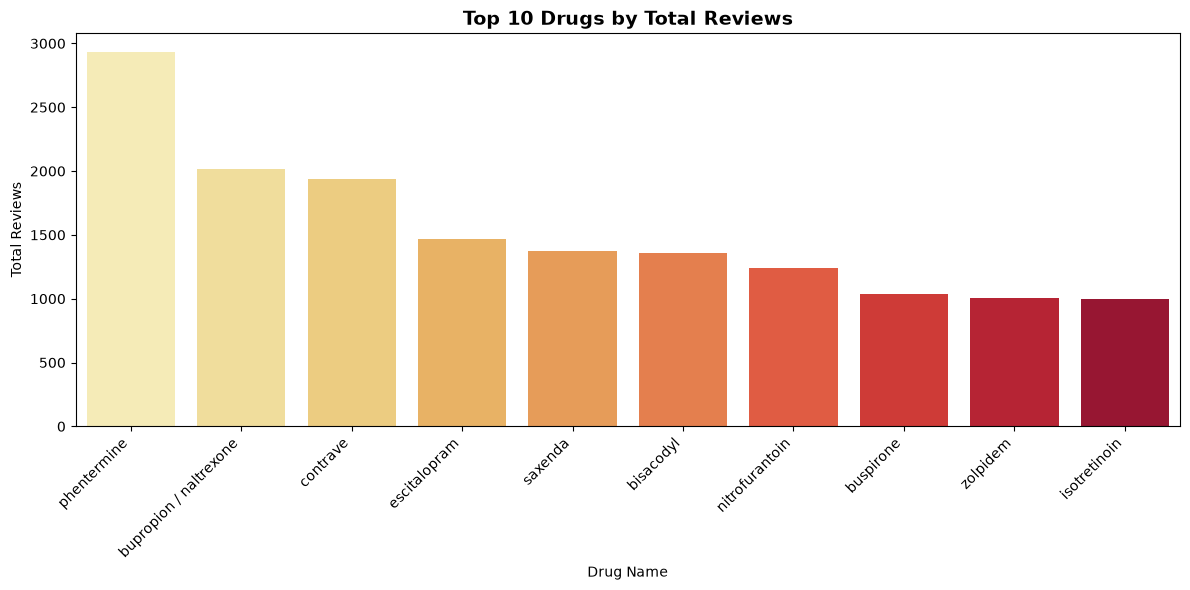

In [28]:
## Exploratory Data Analysis: Visualisations
# Top Reviewed Drugs
# Change dataframe to one row per drug
drug_level = (
    final
    .groupby(
        ["drug_name", "medical_condition", "drug_classes", "rx_otc",
         "pregnancy_category", "csa", "rating", "no_of_reviews"],
        dropna=False
    )
    .agg(n_side_effects=("side_effects", "nunique"))
    .reset_index()
)
drug_reviews = drug_level.groupby("drug_name")["no_of_reviews"].sum().reset_index()
top_reviewed_drugs = drug_reviews.nlargest(10, "no_of_reviews")
fig = create_vbar_plot(
    top_reviewed_drugs,
    x_col="drug_name",
    y_col="no_of_reviews",
    title="Top 10 Drugs by Total Reviews",
    x_label="Drug Name",
    y_label="Total Reviews"
)
plt.show()

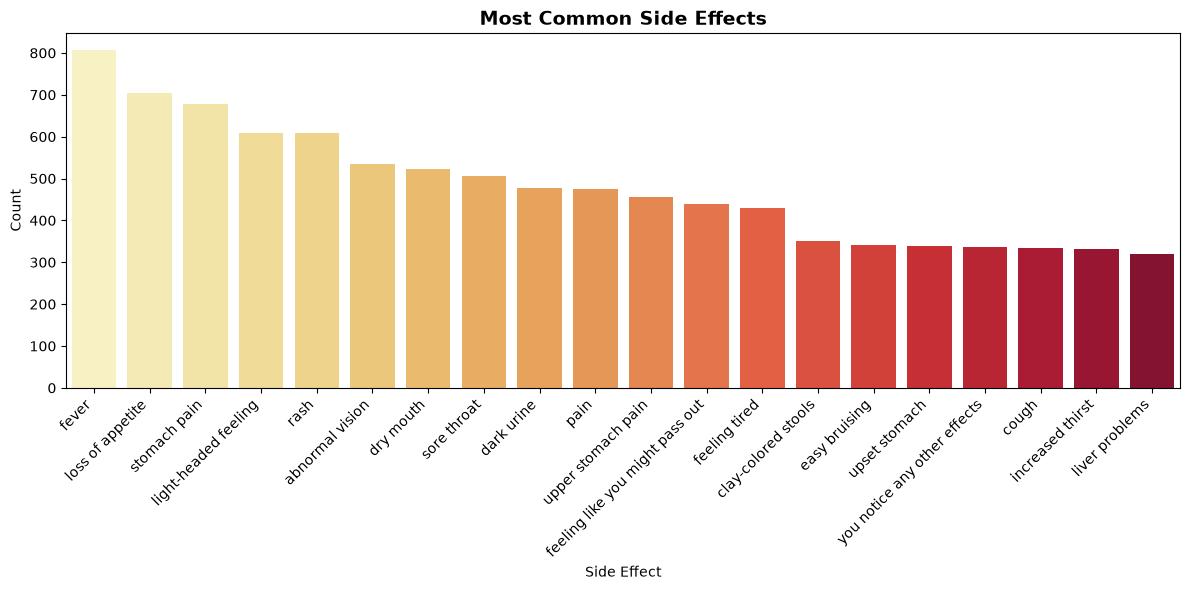

In [29]:
# Most common side effects
top_side_effects = (
    final["side_effects"]
    .value_counts()
    .head(20)
    .reset_index(name="count")
)
top_side_effects.columns = ["side_effects", "count"]

fig = create_vbar_plot(
    top_side_effects,
    x_col="side_effects",
    y_col="count",
    title="Most Common Side Effects",
    x_label="Side Effect",
    y_label="Count"
)
plt.show()

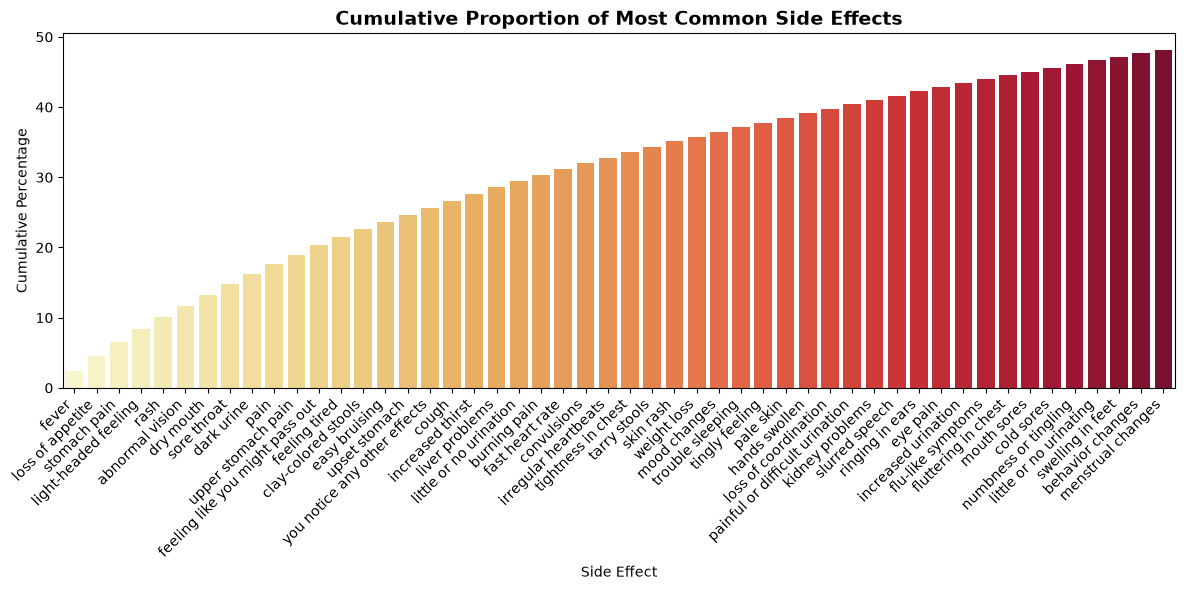

In [30]:
counts = final['side_effects'].value_counts()

top20 = counts.head(50).rename('count').to_frame()

top20['pct'] = top20['count'] / counts.sum() * 100
top20['cum_pct'] = top20['pct'].cumsum()

fig = create_vbar_plot(
    top20,
    x_col="side_effects",
    y_col="cum_pct",
    title="Cumulative Proportion of Most Common Side Effects",
    x_label="Side Effect",
    y_label="Cumulative Percentage"
)
plt.show()

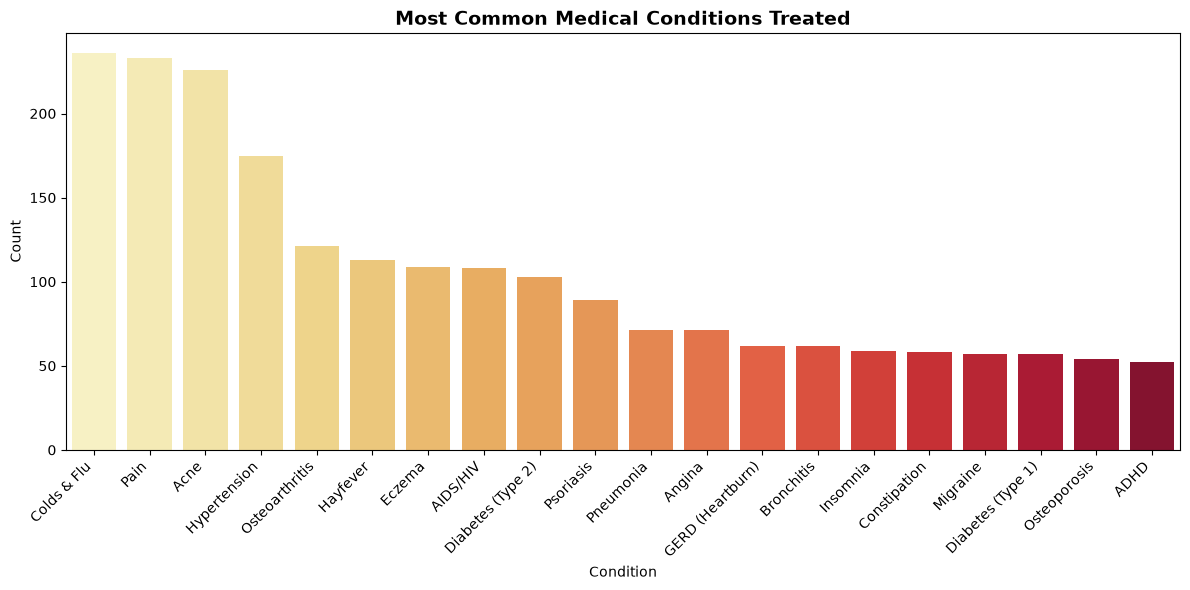

In [31]:
# Top medical conditions with drugs
top_conditions = (
    drug_level["medical_condition"]
    .value_counts()
    .head(20)
    .reset_index(name="count")
)
top_conditions.columns = ["medical_condition", "count"]

fig = create_vbar_plot(
    top_conditions,
    x_col="medical_condition",
    y_col="count",
    title="Most Common Medical Conditions Treated",
    x_label="Condition",
    y_label="Count"
)
plt.show()

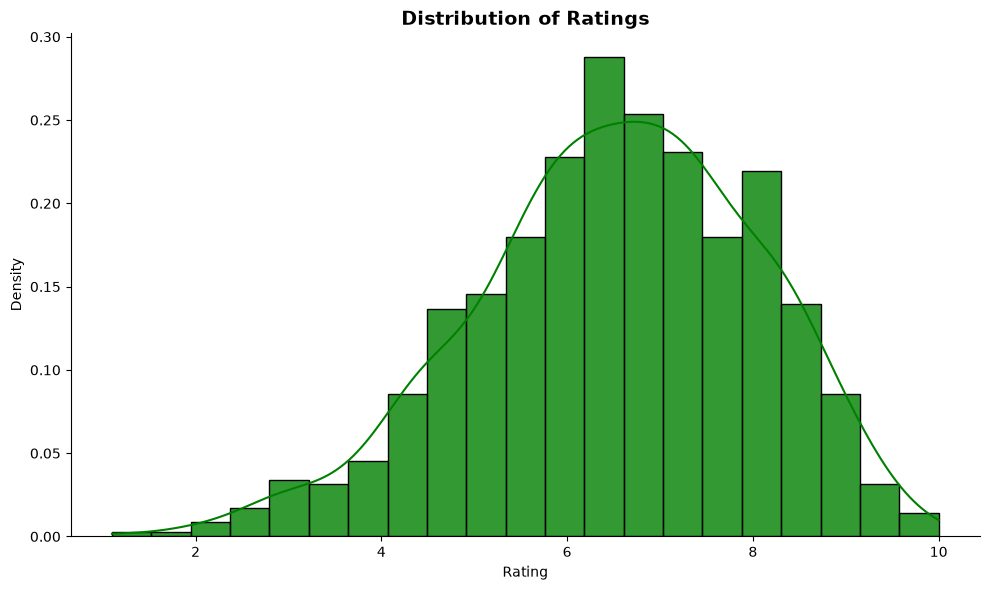

In [32]:
# Distribution of ratings
filtered_df = df[df["no_of_reviews"] > 10]

fig = create_histogram_with_kde(
    filtered_df,
    column='rating',
    title="Distribution of Ratings",
    x_label='Rating',
    y_label='Density',
    color='green'
)
plt.show()

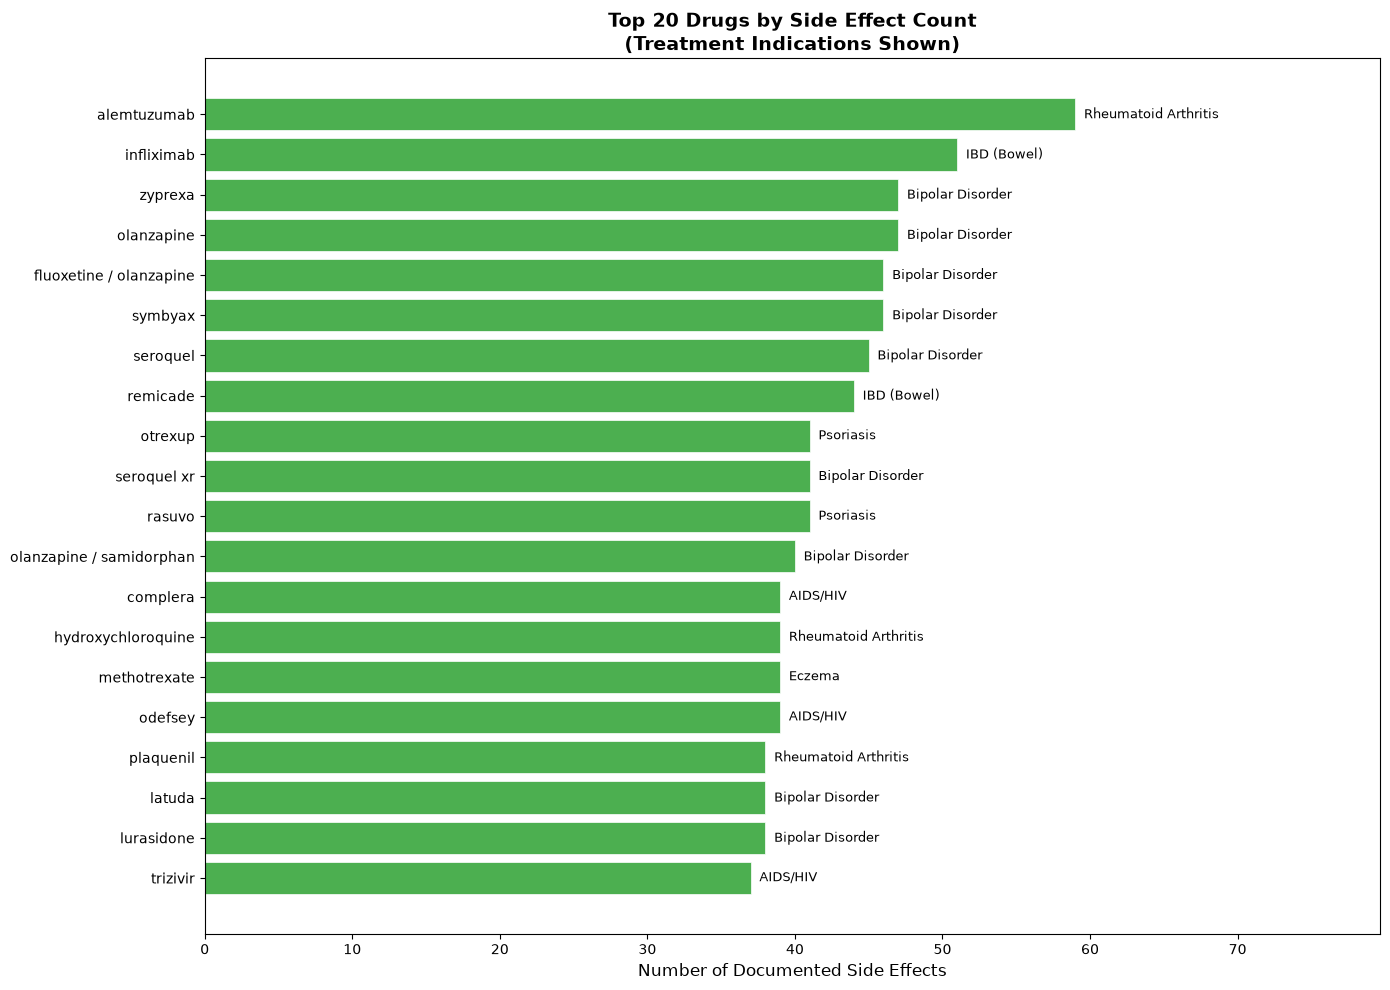

In [33]:
def create_drug_side_effect_plot(plot_data: pd.DataFrame,
                                 figsize: tuple = None) -> plt.Figure:
    """Horizontal bar plot with treatment condition annotations."""
    plot_data = (plot_data
                 .sort_values("n_side_effects", ascending=False)
                 .head(20))

    fig, ax = plt.subplots(figsize=(14, 10))
    max_val = plot_data["n_side_effects"].max()

    ax.barh(plot_data["drug_name"], plot_data["n_side_effects"],
            color=PLOT_CONFIG["bar_color_green"],
            edgecolor="white", linewidth=0.5)

    for pos, (_, row) in enumerate(plot_data.iterrows()):
        cond = str(row["primary_condition"] or "Unknown")
        if len(cond) > 30:
            cond = cond[:30] + "..."
        ax.text(row["n_side_effects"] + max_val * 0.01, pos, cond,
                va="center", ha="left", fontsize=9)

    ax.set_xlim(0, max_val * 1.35)
    ax.set_xlabel("Number of Documented Side Effects", fontsize=12)
    ax.set_title("Top 20 Drugs by Side Effect Count\n(Treatment Indications Shown)",
                 fontsize=14, fontweight="bold")
    ax.invert_yaxis()
    plt.tight_layout()
    return fig

drug_conditions = (
    final.groupby("drug_name")["medical_condition"]
    .agg(lambda x: x.value_counts().index[0] if len(x) > 0 else "Unknown")
    .reset_index()
    .rename(columns={"medical_condition": "primary_condition"})
)

plot_data = drug_level.merge(drug_conditions, on="drug_name")

fig = create_drug_side_effect_plot(plot_data)
plt.show()

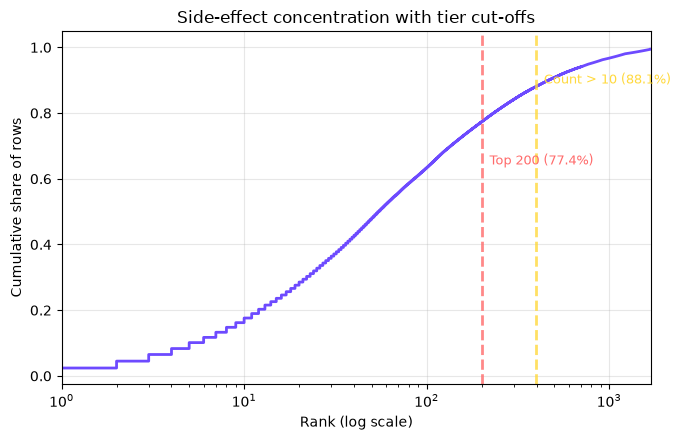

In [40]:
counts = final["side_effects"].value_counts()
total_rows = counts.sum()
cum_share = counts.cumsum() / total_rows

fig, ax = plt.subplots(figsize=(7, 4.5))

ranks = np.arange(1, len(counts) + 1)
ax.plot(ranks, cum_share.values, drawstyle="steps-post", color="#6d4aff", linewidth=2)

# Tier 1 boundary (top 200)
ax.axvline(200, color="#ff6b6b", linestyle="--", linewidth=2, alpha=0.8)
ax.text(200, cum_share.iloc[99], f"  Top 200 ({cum_share.iloc[199]:.1%})",
        va='bottom', fontsize=9, color="#ff6b6b")

# Tier 2 boundary (count > 10)
tier2_rank = len(counts[counts > 10])
ax.axvline(tier2_rank, color="#ffd93d", linestyle="--", linewidth=2, alpha=0.8)
share_tier2 = counts[counts > 10].sum() / total_rows
ax.text(tier2_rank, share_tier2, f"  Count > 10 ({share_tier2:.1%})",
        va='bottom', fontsize=9, color="#ffd93d")

ax.set_xscale("log")
ax.set_xlabel("Rank (log scale)")
ax.set_ylabel("Cumulative share of rows")
ax.set_title("Side-effect concentration with tier cut-offs")
ax.grid(True, alpha=0.3)
ax.set_xlim(1, max(ranks) * 0.9)

plt.tight_layout()
plt.show()

In [36]:
# Filtering df to top 200 side effects and
counts = final["side_effects"].value_counts()
top200 = counts.head(200).index

final_top200_se = final[final["side_effects"].isin(top200)].copy()
final_top200_se["drug_class"] = (
    final_top200_se["drug_classes"]
    .astype(str)
    .str.split("[,;]")
    .str[0]
    .str.strip()
    .str.lower()
)

final_top200_drug = (
    final_top200_se
    .groupby(["drug_name", "medical_condition", "drug_classes", "rx_otc",
              "pregnancy_category", "csa", "rating", "no_of_reviews",
              "drug_class"], dropna=False)
    .agg(n_side_effects=("side_effects", "nunique"))
    .reset_index()
)

print("FILTERED DF:")
print(f'Unique drugs represented: {final_top200_drug["drug_name"].nunique()}')
print(f'Unique medical conditions treated: {final_top200_drug["medical_condition"].nunique()}')
print(f"Total side effects represented: {len(final_top200_se)} ({len(final_top200_se)/len(final):.2%} of the original side effects)")
print(f"Unique side effects: {final_top200_se['side_effects'].nunique()}")

FILTERED DF:
Unique drugs represented: 2702
Unique medical conditions treated: 47
Total side effects represented: 25992 (77.37% of the original side effects)
Unique side effects: 200


In [41]:
final_top200_drug = final_top200_drug[final_top200_drug["drug_class"] != "nan"]

drugs_per_class = (
    final_top200_drug[["drug_name", "drug_class"]]
    .drop_duplicates()
    ["drug_class"]
    .value_counts()
)

print("\nDrug classes with the highest number of drugs:")
print(drugs_per_class.head(10))

print("\nDrug classes with the lowest number of drugs:")
print(drugs_per_class.tail(10))


Drug classes with the highest number of drugs:
drug_class
upper respiratory combinations          241
topical acne agents                     117
topical steroids                         84
nonsteroidal anti-inflammatory drugs     68
laxatives                                52
opioids (narcotic analgesics)            51
antiviral combinations                   50
insulin                                  50
analgesic combinations                   49
miscellaneous topical agents             48
Name: count, dtype: int64

Drug classes with the lowest number of drugs:
drug_class
general anesthetics                      1
mouth and throat products                1
somatostatin and somatostatin analogs    1
antipseudomonal penicillins              1
progestins                               1
cd20 monoclonal antibodies               1
melanocortin receptor agonists           1
thioxanthenes                            1
anticholinergic antiparkinson agents     1
topical antivirals            


Top 10 classes for PCA: ['upper respiratory combinations', 'topical acne agents', 'topical steroids', 'nonsteroidal anti-inflammatory drugs', 'laxatives', 'opioids (narcotic analgesics)', 'antiviral combinations', 'insulin', 'analgesic combinations', 'miscellaneous topical agents']
810 drugs × 174 effects across 10 classes


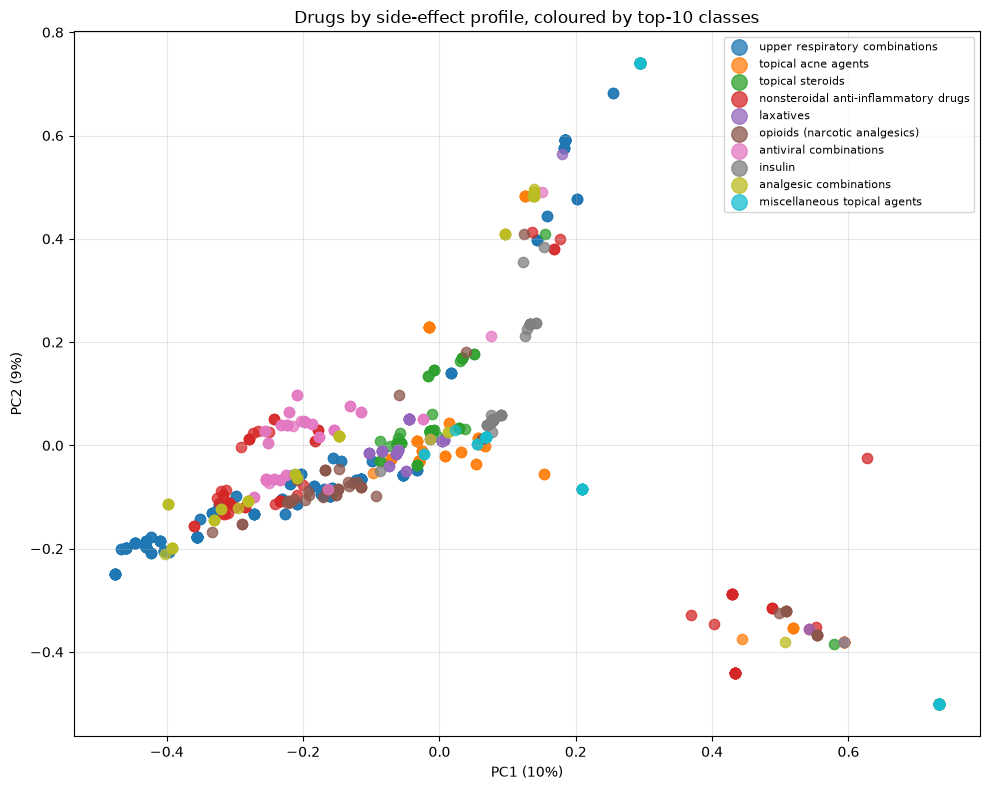

In [ ]:
# Running PCA on the top 10 drug classes represented and the top 200 side effects
top10_classes = drugs_per_class.head(10).index.tolist()
print("\nTop 10 classes for PCA:", top10_classes)

data = final_top200_se[final_top200_se["drug_class"].isin(top10_classes)]

mat = pd.crosstab(data["drug_name"], data["side_effects"], normalize="index")
labels = data.groupby("drug_name")["drug_class"].first().reindex(mat.index)

print(f"{mat.shape[0]} drugs × {mat.shape[1]} effects across {labels.nunique()} classes")

mat_t = np.sqrt(mat)
pca = PCA(random_state=42)
coords = pca.fit_transform(mat_t)

fig, ax = plt.subplots(figsize=(10, 8))

for cls in top10_classes:
    m = (labels == cls).values
    if m.sum() == 0:
        continue
    ax.scatter(coords[m, 0], coords[m, 1], s=55, alpha=0.75, label=cls)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Drugs by side-effect profile, coloured by top-10 classes")
ax.legend(fontsize=8, markerscale=1.5)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()